# MMIP HW7 作業 B：兩個開源視覺多模態大模型

比較 `Qwen/Qwen2.5-VL-3B-Instruct` 與 `HuggingFaceTB/SmolVLM2-2.2B-Instruct`。兩者依序載入、使用完全相同的 20 張影像、問題、prompt 與 greedy decoding，並以事先固定的答案進行量化評分。


In [1]:
%%capture
!pip -q install "transformers>=4.57,<5" "huggingface-hub>=0.34,<1" accelerate pillow num2words pandas matplotlib seaborn tabulate

In [2]:
import gc, json, platform, random, re, time, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
import transformers
from transformers import AutoModelForImageTextToText, AutoProcessor

assert torch.cuda.is_available(), "請在 Colab 啟用 GPU。"
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
MODELS=["Qwen/Qwen2.5-VL-3B-Instruct","HuggingFaceTB/SmolVLM2-2.2B-Instruct"]
OUT=Path("outputs_B"); OUT.mkdir(exist_ok=True)
print({"python":platform.python_version(),"torch":torch.__version__,"transformers":transformers.__version__,"gpu":torch.cuda.get_device_name(0)})

{'python': '3.13.16', 'torch': '2.11.0+cu130', 'transformers': '4.57.6', 'gpu': 'Tesla T4'}


## 1. 驗證 20 題視覺 Benchmark

圖片由 Pillow 固定程式產生，避免網路資料漂移與授權問題。能力涵蓋顏色、形狀、計數、空間關係、大小比較、OCR、圖表及混合場景。


In [3]:
bench_path=Path("vlm_benchmark.json")
image_dir=Path("vlm_benchmark_images")
image_zip=Path("vlm_benchmark_images.zip")
if not image_dir.exists() and image_zip.exists():
    with zipfile.ZipFile(image_zip) as zf:
        zf.extractall(".")
if not bench_path.exists() or not image_dir.exists():
    raise FileNotFoundError("請上傳 vlm_benchmark.json，以及 vlm_benchmark_images/ 或 vlm_benchmark_images.zip")
bench=json.loads(bench_path.read_text(encoding="utf-8"))
assert len(bench)==20 and len({x["id"] for x in bench})==20
missing=[x["image"] for x in bench if not Path(x["image"]).exists()]
assert not missing, f"缺少影像：{missing}"
display(pd.DataFrame(bench)[["id","category","question","answer"]])

,id,category,question,answer
0,color_01,color,What color is the circle? Answer with one lowe...,red
1,color_02,color,What color is the square? Answer with one lowe...,blue
2,shape_01,shape,"What shape is shown? Answer circle, square, or...",triangle
3,shape_02,shape,"What shape is shown? Answer circle, square, or...",square
4,count_01,counting,How many red circles are shown? Answer with a ...,3
5,count_02,counting,How many blue squares are shown? Answer with a...,4
6,count_03,counting,How many green triangles are shown? Answer wit...,2
7,position_01,spatial,Is the red circle left or right of the blue sq...,left
8,position_02,spatial,Is the yellow triangle above or below the purp...,above
9,compare_01,comparison,"Which shape is larger, circle or square? Answe...",circle


## 2. 共用 Prompt、推論及評分

所有題目共享同一個 system prompt，個別題目的 question 亦完全相同。評分採正規化後 exact match；這些題目刻意限制短答案，使兩模型可公平自動評估。


In [4]:
SYSTEM="Answer the visual question using only the requested short answer. Do not explain and do not use Markdown."
def norm(x):
    x=x.strip().lower().replace("，",",")
    x=re.sub(r"^(answer\s*[:：]\s*)","",x)
    return re.sub(r"[.!。\s]+$","",x)

@torch.inference_mode()
def infer(model,processor,item):
    image_path=str(Path(item["image"]).resolve())
    messages=[
      {"role":"system","content":[{"type":"text","text":SYSTEM}]},
      {"role":"user","content":[{"type":"image","path":image_path},{"type":"text","text":item["question"]}]}
    ]
    inputs=processor.apply_chat_template(messages,add_generation_prompt=True,tokenize=True,return_dict=True,return_tensors="pt").to(model.device)
    input_len=inputs["input_ids"].shape[-1]
    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats(); t=time.perf_counter()
    out=model.generate(**inputs,max_new_tokens=32,do_sample=False)
    torch.cuda.synchronize(); latency=time.perf_counter()-t
    text=processor.decode(out[0,input_len:],skip_special_tokens=True).strip()
    return text,latency,torch.cuda.max_memory_allocated()/2**30

def evaluate_model(model_id):
    print("Loading",model_id)
    processor=AutoProcessor.from_pretrained(model_id)
    model=AutoModelForImageTextToText.from_pretrained(model_id,dtype=torch.float16,device_map={"":0},low_cpu_mem_usage=True).eval()
    rows=[]
    try:
        for i,item in enumerate(bench,1):
            output,latency,peak=infer(model,processor,item)
            rows.append({**item,"model":model_id,"output":output,"score":float(norm(output)==norm(item["answer"])),"latency_sec":latency,"peak_gpu_gib":peak})
            print(f"{i:02d}/20 {item['id']} expected={item['answer']!r} output={output!r}")
        footprint=model.get_memory_footprint()/2**30
        return pd.DataFrame(rows),footprint
    finally:
        del model,processor
        gc.collect(); torch.cuda.empty_cache()

## 3. 依序執行兩個開源 VLM

依序而非同時載入可避免 T4 OOM，且不影響公平性。


In [5]:
frames=[]
footprints={}
for model_id in MODELS:
    frame,footprint=evaluate_model(model_id)
    assert len(frame)==20, f"{model_id} 僅完成 {len(frame)} 題"
    frames.append(frame)
    footprints[model_id]=footprint
results=pd.concat(frames,ignore_index=True)
assert len(results)==40
assert set(results.model)==set(MODELS)
assert results.groupby("model").size().eq(20).all()
assert results.groupby(["model","id"]).size().eq(1).all()
results.to_csv(OUT/"vlm_results.csv",index=False,encoding="utf-8-sig")
display(results.groupby("model")["score"].agg(["count","mean"]))

Loading Qwen/Qwen2.5-VL-3B-Instruct


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

The image processor of type `Qwen2VLImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. Note that this behavior will be extended to all models in a future release.


tokenizer_config.json: 0.00B [00:00, ?B/s]

...

model-00002-of-00002.safetensors:   0%|          | 0.00/4.03G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

01/20 color_01 expected='red' output='red'
02/20 color_02 expected='blue' output='blue'
03/20 shape_01 expected='triangle' output='triangle'
04/20 shape_02 expected='square' output='square'
05/20 count_01 expected='3' output='3'
06/20 count_02 expected='4' output='4'
07/20 count_03 expected='2' output='2'
08/20 position_01 expected='left' output='Left.'
09/20 position_02 expected='above' output='Above.'
10/20 compare_01 expected='circle' output='Circle.'
11/20 ocr_01 expected='HELLO 27' output='27'
12/20 ocr_02 expected='OPEN 09:30' output='Open 09:30.'
13/20 ocr_03 expected='ROOM B12' output='ROOM B12'
14/20 chart_01 expected='B' output='B.'
15/20 chart_02 expected='Y' output='Y.'
16/20 mixed_01 expected='3' output='4'
17/20 mixed_02 expected='yes' output='Yes.'
18/20 mixed_03 expected='2' output='2'
19/20 mixed_04 expected='orange' output='orange'
20/20 mixed_05 expected='square' output='square'


,count,mean
model,,
HuggingFaceTB/SmolVLM2-2.2B-Instruct,20,0.9
Qwen/Qwen2.5-VL-3B-Instruct,20,1.0


## 4. 指標、圖表與報告

主要指標為 exact-match accuracy，同時呈現分類別正確率、平均延遲與平均 GPU 峰值。


,model,accuracy,avg_latency_sec,avg_peak_gpu_gib,accuracy_pct,model_footprint_gib
0,HuggingFaceTB/SmolVLM2-2.2B-Instruct,0.9,1.054,4.607,90.0,4.185
1,Qwen/Qwen2.5-VL-3B-Instruct,1.0,0.571,7.069,100.0,6.994


model,HuggingFaceTB/SmolVLM2-2.2B-Instruct,Qwen/Qwen2.5-VL-3B-Instruct
category,,
chart,1.00,1.0
color,1.00,1.0
comparison,1.00,1.0
counting,1.00,1.0
mixed,0.80,1.0
ocr,0.67,1.0
shape,1.00,1.0
spatial,1.00,1.0


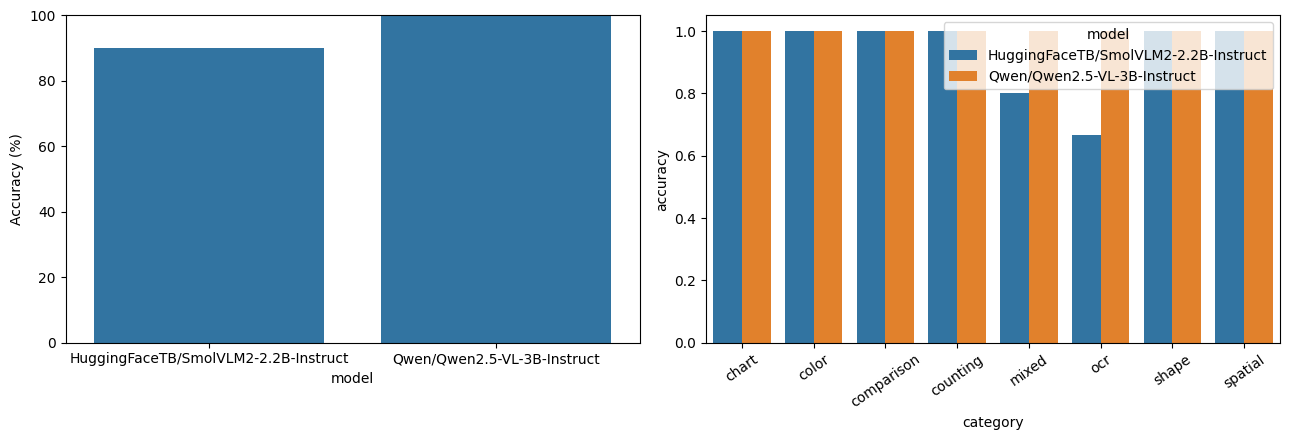

In [6]:
summary=(results.groupby("model",as_index=False).agg(accuracy=("score","mean"),avg_latency_sec=("latency_sec","mean"),avg_peak_gpu_gib=("peak_gpu_gib","mean")))
summary["accuracy_pct"]=summary.accuracy*100
summary["model_footprint_gib"]=summary.model.map(footprints)
category=results.groupby(["model","category"],as_index=False).agg(accuracy=("score","mean"))
summary.to_csv(OUT/"summary.csv",index=False,encoding="utf-8-sig"); category.to_csv(OUT/"category_summary.csv",index=False,encoding="utf-8-sig")
display(summary.round(3)); display(category.pivot(index="category",columns="model",values="accuracy").round(2))

fig,ax=plt.subplots(1,2,figsize=(13,4.5))
sns.barplot(data=summary,x="model",y="accuracy_pct",ax=ax[0]); ax[0].set_ylim(0,100); ax[0].set_ylabel("Accuracy (%)")
sns.barplot(data=category,x="category",y="accuracy",hue="model",ax=ax[1]); ax[1].tick_params(axis="x",rotation=35)
plt.tight_layout(); plt.savefig(OUT/"vlm_comparison.png",dpi=180,bbox_inches="tight"); plt.show()

In [7]:
table=summary.round(3).to_markdown(index=False)
winner=summary.loc[summary.accuracy.idxmax(),"model"]
report=f"""# 作業 B：視覺多模態大模型比較

## 方法
本實驗部署兩個 Apache-2.0 開源 VLM：{MODELS[0]} 與 {MODELS[1]}。使用 20 道自建合成影像 benchmark，兩模型的影像、問題、system prompt、greedy decoding 與 max_new_tokens 完全相同。主要量化指標為 exact-match accuracy。

## 結果
{table}

本 benchmark 正確率較高者為 **{winner}**。分類別結果見 `category_summary.csv`；逐題原始輸出見 `vlm_results.csv`，因此失敗案例可稽核。

![比較圖](vlm_comparison.png)

## 限制
合成影像能精確控制答案，但不代表自然影像的全部難度；exact match 對同義詞較嚴格。結論只適用於本 20 題 benchmark，不應外推為模型整體排名。
"""
(OUT/"report_B.md").write_text(report,encoding="utf-8"); print(report)

# 作業 B：視覺多模態大模型比較

## 方法
本實驗部署兩個 Apache-2.0 開源 VLM：Qwen/Qwen2.5-VL-3B-Instruct 與 HuggingFaceTB/SmolVLM2-2.2B-Instruct。使用 20 道自建合成影像 benchmark，兩模型的影像、問題、system prompt、greedy decoding 與 max_new_tokens 完全相同。主要量化指標為 exact-match accuracy。

## 結果
| model                                |   accuracy |   avg_latency_sec |   avg_peak_gpu_gib |   accuracy_pct |   model_footprint_gib |
|:-------------------------------------|-----------:|------------------:|-------------------:|---------------:|----------------------:|
| HuggingFaceTB/SmolVLM2-2.2B-Instruct |        0.9 |             1.054 |              4.607 |             90 |                 4.185 |
| Qwen/Qwen2.5-VL-3B-Instruct          |        1   |             0.571 |              7.069 |            100 |                 6.994 |

本 benchmark 正確率較高者為 **Qwen/Qwen2.5-VL-3B-Instruct**。分類別結果見 `category_summary.csv`；逐題原始輸出見 `vlm_results.csv`，因此失敗案例可稽核。

![比較圖](vlm_comparison.png)

## 限制
合成影像能精確控制答案，但不代表自然影像的全部難度；exact match 對同義詞較嚴格。結論只適用於本 20 題 b

In [8]:
assert len(results)==40
assert results["id"].nunique()==20
assert set(results["model"])==set(MODELS)
assert results.groupby("model").size().eq(20).all()
assert results.groupby(["model","id"]).size().eq(1).all()
assert results.score.isin([0.,1.]).all()
assert results.output.notna().all()
metadata={"python":platform.python_version(),"torch":torch.__version__,"transformers":transformers.__version__,"gpu":torch.cuda.get_device_name(0),"seed":SEED,"decoding":"greedy","max_new_tokens":32}
(OUT/"environment.json").write_text(json.dumps(metadata,indent=2,ensure_ascii=False),encoding="utf-8")
print("✅ 作業 B 完整性檢查通過：兩個模型各 20 題，共 40 筆")


✅ 作業 B 完整性檢查通過：兩個模型各 20 題，共 40 筆
